In [1]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.preprocessing import StandardScaler
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold, ValidationCurveDisplay
import pandas as pd
from langdetect import detect, DetectorFactory
import matplotlib.pyplot as plt
import unicodedata
from sentence_transformers import SentenceTransformer
from sklearn.base import BaseEstimator, TransformerMixin
import nltk
from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import roc_auc_score, f1_score, classification_report, confusion_matrix, \
    ConfusionMatrixDisplay
import numpy as np
from sklearn.metrics import roc_curve, auc, precision_recall_curve
from sklearn.preprocessing import label_binarize
from langdetect import LangDetectException
import re
from sklearn.model_selection import train_test_split
import emoji
import simplemma
from nltk import word_tokenize
from emosent import get_emoji_sentiment_rank

C:\Users\lucas\OneDrive\Escritorio\TP 1 tweets\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
df = pd.read_csv("./ia_tweets.csv")

df.head()

,ID,text,polarity,favorite_count,retweet_count,user_followers_count,user_friends_count,user_favourites_count,user_statuses_count,user_verified,user_has_extended_profile,user_is_translator,user_protected,user_default_profile
0,0,Comentaba en una charla sobre IA que el proble...,N,21,7,15936,2395,66945,68578,0,1,0,0,0
1,1,"@alvaropons Eso es imposible. Y sí, va a gener...",N,1,0,685,851,169490,128555,0,1,0,0,1
2,2,@alvaropons Lo disruptivo es que tras años de ...,NEU,1,0,685,851,169490,128555,0,1,0,0,1
3,3,"@alvaropons ¿""Prohibición del uso comercial de...",N,0,0,4877,538,6123,3156,0,1,0,0,0
4,4,@santoroydonoso Cómo se está estudiando prohib...,NEU,0,0,15936,2395,66945,68578,0,1,0,0,0


In [3]:
df.dtypes

ID                           int64
text                           str
polarity                       str
favorite_count               int64
retweet_count                int64
user_followers_count         int64
user_friends_count           int64
user_favourites_count        int64
user_statuses_count          int64
user_verified                int64
user_has_extended_profile    int64
user_is_translator           int64
user_protected               int64
user_default_profile         int64
dtype: object

In [4]:
DetectorFactory.seed = 0

def idioma(texto):
    try:
        return detect(str(texto))
    except LangDetectException:
        return "es"

df['idioma'] = df['text'].map(idioma)

df = df[df["idioma"] == "es"]

df = df.drop(columns=["ID","user_has_extended_profile", "user_is_translator", "user_protected", "idioma"])

print("Tweets conservados:", len(df))

Tweets conservados: 3660


In [5]:
def filtrar_por_polaridad(field):
    return df[df["polarity"] == field]

cant_negativos = len(filtrar_por_polaridad("N"))
cant_neutros = len(filtrar_por_polaridad("NEU"))
cant_positivos =  len(filtrar_por_polaridad("P"))

print('Cantidad de tweets: ', len(df))
print('Tweets Negativos: ', cant_negativos, ', Neutros' , cant_neutros,', Positivos', cant_positivos)

# Cantidad de datos desbalanceada, se tiene mucho mas datos neutros que negativos o positivos.

Cantidad de tweets:  3660
Tweets Negativos:  551 , Neutros 2417 , Positivos 692


In [6]:
cantidad_na = df.isna().sum()
print(cantidad_na)

#(cantidad_negativos_columna("favorite_count"))

# No hay nulls o valores

text                     0
polarity                 0
favorite_count           0
retweet_count            0
user_followers_count     0
user_friends_count       0
user_favourites_count    0
user_statuses_count      0
user_verified            0
user_default_profile     0
dtype: int64


In [7]:
cantidad_negativos = (df.select_dtypes(include='number') < 0).sum()
print(cantidad_negativos)

favorite_count           0
retweet_count            0
user_followers_count     0
user_friends_count       0
user_favourites_count    0
user_statuses_count      0
user_verified            0
user_default_profile     0
dtype: int64


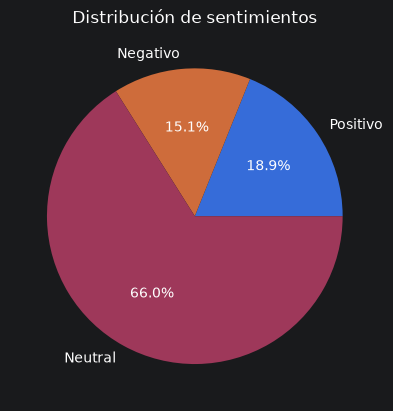

In [8]:
# Datos
clases = ['Positivo', 'Negativo', 'Neutral']
cantidades = [cant_positivos, cant_negativos, cant_neutros]

# Crear gráfico
plt.pie(cantidades, labels=clases, autopct='%1.1f%%')
plt.title('Distribución de sentimientos')
plt.show()

4.1519125683060105
2243
0


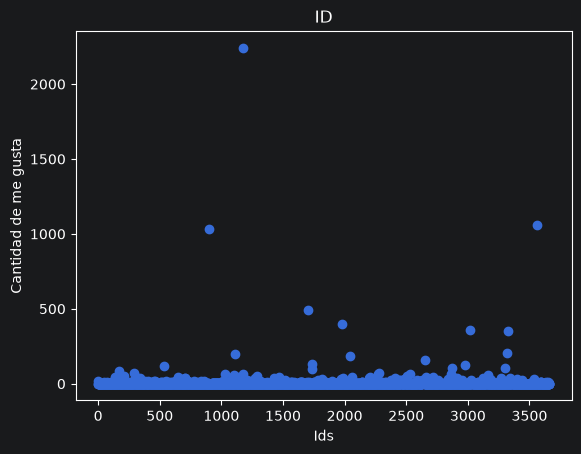

In [9]:
print(df["favorite_count"].mean())
print(df["favorite_count"].max())
print(df["favorite_count"].min())

plt.scatter(range(0,len(df)), df['favorite_count'])

plt.xlabel('Ids')
plt.ylabel('Cantidad de me gusta')
plt.title('ID')

plt.show()

0.9606557377049181
502
0


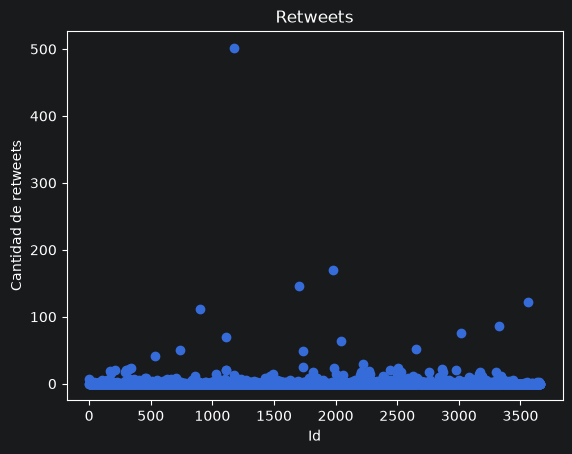

In [10]:
print(df["retweet_count"].mean())
print(df["retweet_count"].max())
print(df["retweet_count"].min())

plt.scatter(range(0,len(df)), df['retweet_count'])

plt.xlabel('Id')
plt.ylabel('Cantidad de retweets')
plt.title('Retweets')

plt.show()

Cantidad de tweets positivo con interaccion:  172
Cantidad de tweets negativos con interaccion:  139
Media de interacciones en positivos:  6.726878612716763
Media de interacciones en negativos:  3.8747731397459164


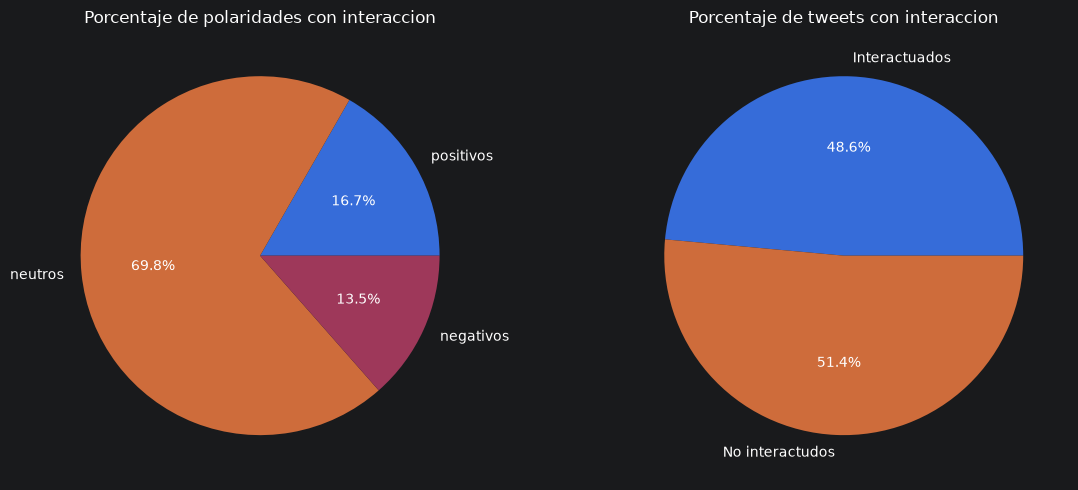

In [11]:
df['tweet_interactions'] = df['favorite_count'] + df['retweet_count']

tweets_con_interaccion = (df['tweet_interactions'] > 0).sum()
tweets_sin_interaccion = (df['tweet_interactions'] == 0).sum()

positivos_con_interaccion = (df[df['polarity'] == 'P']['tweet_interactions'] > 1).sum()
neutros_con_interaccion = (df[df['polarity'] == 'NEU']['tweet_interactions'] > 1).sum()
negativos_con_interaccion = (df[df['polarity'] == 'N']['tweet_interactions'] > 1).sum()
interaccion_positivos_media = df[df['polarity'] == 'P']['tweet_interactions'].mean()
interaccion_negativos_media = df[df['polarity'] == 'N']['tweet_interactions'].mean()

print("Cantidad de tweets positivo con interaccion: ", positivos_con_interaccion)
print("Cantidad de tweets negativos con interaccion: ", negativos_con_interaccion)
print("Media de interacciones en positivos: ", interaccion_positivos_media)
print("Media de interacciones en negativos: ", interaccion_negativos_media)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].pie([positivos_con_interaccion, neutros_con_interaccion, negativos_con_interaccion], labels=["positivos", "neutros", "negativos"], autopct='%1.1f%%')
ax[0].set_title('Porcentaje de polaridades con interaccion')

ax[1].pie([tweets_con_interaccion, tweets_sin_interaccion],
  labels=["Interactuados", "No interactudos"], autopct='%1.1f%%')
ax[1].set_title('Porcentaje de tweets con interaccion')

plt.tight_layout()
plt.show()

In [12]:
 #text
#polarity
#favorite_count
#retweet_count
#user_followers_count
#user_friends_count
#user_favourites_count         TEST (Likes que dio)
#user_statuses_count           TEST (Publicaciones y comentarios suyos)
#user_verified                 TEST
#user_default_profile          TEST (Pagina de perfil default)


def contar_emojis(texto):
    return sum(1 for caracter in str(texto) if unicodedata.category(caracter) == 'So')

df["length"] = df['text'].apply(lambda texto: len(texto.split()))
df["hashtag_count"] = df['text'].apply(lambda texto: texto.count('#'))
df["mention_count"] = df['text'].apply(lambda texto: texto.count('@'))
df["url_count"] = df['text'].apply(lambda texto: texto.count('http'))
df["punctuation_count"] = df['text'].apply(lambda texto: texto.count('?') + texto.count('!'))
df['emoji_count'] = df['text'].apply(contar_emojis)

# :url: :mencion:

#Campos extra
#Longitud (palabras)
#Cantidad de hashtags
#Cantidad de usuarios mencionados
#Cantidad de emojis
#Cantidad de urls
#Cantidad de signos de exclamacion/interrogacion

In [13]:

URL_RE = re.compile(r"https?://\S+|www\.\S+", re.IGNORECASE)
MENTION_RE = re.compile(r"@\w+")
HASHTAG_RE = re.compile(r"#(\w+)")


def _separar_hashtag(match):
    """#InteligenciaArtificial -> Inteligencia Artificial."""
    palabra = match.group(1)
    return " " + re.sub(r"(?<=[a-záéíóúüñ])(?=[A-ZÁÉÍÓÚÑ])", " ", palabra) + " "


def normalizar_texto(texto):
    """Normaliza sin perder informacion util para el modelo.

    - NFC conserva tildes y enes en una forma canonica.
    - URLs, menciones y hashtags se reemplazan por tokens explicitos.
    - El hashtag conserva su palabra para no perder el tema del tweet.
    """
    texto = unicodedata.normalize("NFC", str(texto))
    texto = URL_RE.sub(" URL ", texto)
    texto = MENTION_RE.sub(" MENCION ", texto)
    texto = HASHTAG_RE.sub(_separar_hashtag, texto)
    texto = re.sub(r"\s+", " ", texto).strip()
    return texto


df["text"] = df["text"].map(normalizar_texto)

df.head()

,text,polarity,favorite_count,retweet_count,user_followers_count,user_friends_count,user_favourites_count,user_statuses_count,user_verified,user_default_profile,tweet_interactions,length,hashtag_count,mention_count,url_count,punctuation_count,emoji_count
0,Comentaba en una charla sobre IA que el proble...,N,21,7,15936,2395,66945,68578,0,0,28,44,0,0,1,0,0
1,"MENCION Eso es imposible. Y sí, va a generar u...",N,1,0,685,851,169490,128555,0,1,1,41,0,1,0,0,0
2,MENCION Lo disruptivo es que tras años de deci...,NEU,1,0,685,851,169490,128555,0,1,1,39,0,1,0,0,0
3,"MENCION ¿""Prohibición del uso comercial de las...",N,0,0,4877,538,6123,3156,0,0,0,17,0,1,0,1,0
4,MENCION Cómo se está estudiando prohibir chatG...,NEU,0,0,15936,2395,66945,68578,0,0,0,39,0,1,0,1,0


In [14]:
def emoji_features(text):
    scores = []
    for e in emoji.emoji_list(str(text)):
        try:
            rank = get_emoji_sentiment_rank(e["emoji"])
        except KeyError:
            rank = None
        if rank is not None:
            scores.append(rank["sentiment_score"])
    if not scores:
        return 0.0, 0, 0
    return (
        sum(scores) / len(scores),
        sum(s > 0.1 for s in scores),
        sum(s < -0.1 for s in scores),
    )

df[["emoji_score", "emoji_pos", "emoji_neg"]] = df["text"].apply(
    lambda t: pd.Series(emoji_features(t))
)

df = df.drop(columns=["emoji_score", "emoji_count", "tweet_interactions", "mention_count", "user_followers_count", "user_default_profile", "user_verified"])

In [15]:
X = df.drop(columns=["polarity"])
y = df["polarity"]

# 60% para train y 40% para test y validacion
X_train, X_test_val, y_train, y_test_val = train_test_split(
    X, y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

# Segunda división: separar test y validación
X_test, X_val, y_test, y_val = train_test_split(
    X_test_val, y_test_val,
    test_size=0.5,
    random_state=42,
    stratify=y_test_val
)

print(len(X_train)/len(df))

0.6


In [16]:
number_columns = ["user_statuses_count", "length",
    "emoji_pos", "user_friends_count", "user_favourites_count", "emoji_neg",
    "favorite_count", "retweet_count", "hashtag_count", "url_count"
]

#y_train = pd.get_dummies(y_train, columns=["polarity"], dtype=int)

X_train.head()
y_train.head()

1468    NEU
3145    NEU
2137    NEU
3883    NEU
2562    NEU
Name: polarity, dtype: str

In [17]:
nltk.download('stopwords', quiet=True)
nltk.download('punkt_tab', quiet=True)

STOP_WORDS = set(stopwords.words('spanish'))

class TextCleaner(BaseEstimator, TransformerMixin):
    def __init__(self, method=None):
        self.method = method

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        stemmer = SnowballStemmer('spanish')
        clean_X = []
        for text in X:
            text = normalizar_texto(text)

            text = text.lower()

            tokens = word_tokenize(text, language='spanish')

            tokens = [t for t in tokens if t not in STOP_WORDS]


            if self.method == 'stem':
                tokens = [stemmer.stem(t) for t in tokens]
            elif self.method == 'lemma':
                tokens = [simplemma.lemmatize(t, lang='es')for t in tokens]

            clean_X.append(" ".join(tokens))
        return clean_X


class LightCleaner(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        clean_X = []
        for text in X:
            text = normalizar_texto(text)
            text = re.sub(r"\s+", " ", text).strip()
            clean_X.append(text)
        return clean_X

In [18]:
class EmbeddingTransformer(BaseEstimator, TransformerMixin):
    # Alternativas especificas de espanol para comparar:
    #   - hiiamsid/sentence_similarity_spanish_es
    #   - PlanTL-GOB-ES/roberta-base-bne (requiere mean pooling)
    # Cache a nivel de CLASE: sobrevive a los clones que arma GridSearchCV
    # Clave: (nombre_del_modelo, texto) -> vector
    # El modelo es multilingue (incluye espanol) y trae su propio tokenizador.
    _cache = {}

    def __init__(self, model_name='hiiamsid/sentence_similarity_spanish_es'):
        self.model_name = model_name

    def fit(self, X, y=None):
        # Cargamos el modelo aqui para evitar errores de serializacion
        if not hasattr(self, "model_"):
            self.model_ = SentenceTransformer(self.model_name)
        return self

    def transform(self, X):
        # Permite usar el transformador aunque se lo llame sin fit previo.
        if not hasattr(self, "model_"):
            self.fit(X)

        # Convertimos la lista de textos en una matriz de vectores (Embeddings)
        # Esto implementa implicitamente el "Mean Pooling"
        # Solo calculamos los textos que aun no estan en la cache
        texts = list(X)
        faltantes = [t for t in texts if (self.model_name, t) not in self._cache]
        if faltantes:
            vectores = self.model_.encode(faltantes, show_progress_bar=False)
            for t, v in zip(faltantes, vectores):
                self._cache[(self.model_name, t)] = v
        return np.array([self._cache[(self.model_name, t)] for t in texts])

embedding = EmbeddingTransformer()

In [19]:
from sklearn.svm import LinearSVC
from sklearn.multiclass import OneVsOneClassifier


class ColumnSelector(BaseEstimator, TransformerMixin):
    """Selecciona un subconjunto de columnas por nombre (para iterar features en el grid)."""
    def __init__(self, columns=None):
        self.columns = columns

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        return X[self.columns]

preprocessor = ColumnTransformer([
    (
        'text',
         Pipeline([
            ("cleaner", LightCleaner()),
            ("embedding", EmbeddingTransformer())
        ]),
         'text'),
    (
        "numeric",
        Pipeline([
            ("select", ColumnSelector(number_columns)), #El grid varia que columnas numericas usan
            ("imputer", SimpleImputer(strategy="median")), #Completa datos faltantes
            ("scaler", StandardScaler())
        ]),
        number_columns
    ),
])

pipeline = Pipeline([
    ("classifier", LinearSVC(max_iter=5000))
])

preprocessor.fit(X_test)
X_trval = pd.concat([X_train, X_val])
y_trval = np.concatenate([y_train, y_val])
X_trval_prepro = preprocessor.transform(X_trval)
X_test_prepro = preprocessor.transform(X_test)


24236 | INFO | No device provided, using cpu
24236 | INFO | HTTP Request: HEAD https://huggingface.co/hiiamsid/sentence_similarity_spanish_es/resolve/main/modules.json "HTTP/1.1 307 Temporary Redirect"
24236 | WARNING | Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.
24236 | INFO | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/hiiamsid/sentence_similarity_spanish_es/66ab46adac3910bb6ea6085b962a25e49513b981/modules.json?%2Fhiiamsid%2Fsentence_similarity_spanish_es%2Fresolve%2Fmain%2Fmodules.json=&etag=%22f7640f94e81bb7f4f04daf1668850b38763a13d9%22 "HTTP/1.1 200 OK"
24236 | INFO | HTTP Request: GET https://huggingface.co/api/resolve-cache/models/hiiamsid/sentence_similarity_spanish_es/66ab46adac3910bb6ea6085b962a25e49513b981/modules.json?%2Fhiiamsid%2Fsentence_similarity_spanish_es%2Fresolve%2Fmain%2Fmodules.json=&etag=%22f7640f94e81bb7f4f04daf1668850b38763a13d9%22 "HTTP/1.1 200

In [20]:
from sklearn.model_selection import PredefinedSplit

param_grid = [
    {
        "classifier": [
            OneVsRestClassifier(
                SVC(max_iter=-1)
            ),
            OneVsOneClassifier(
                SVC(max_iter=-1)
            )
        ],
        "classifier__estimator__kernel": ["linear", "rbf"],
        "classifier__estimator__C": [0.1, 0.5, 1, 1.5, 2, 2.5, 3, 3.5, 4, 4.5, 5],
        "classifier__estimator__gamma": [
            "scale", 1e-4, 1e-3, 1e-2, 0.1
        ],
        "classifier__estimator__class_weight": [
            None, "balanced"
        ],
    },
]


cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
grid_search_svm = GridSearchCV(
    pipeline, param_grid, cv=cv, scoring="f1_macro",
    n_jobs=-1, return_train_score=True, verbose=3
)

## Seccion Red neuronal

In [21]:
import keras
from keras import layers

def build_model(meta, units=512, n_layers=1, dropout=0.3,
                activation="sigmoid", learning_rate=1e-3, device=None):
    model = keras.Sequential()
    model.add(keras.Input(shape=(meta["n_features_in_"],)))
    for _ in range(n_layers):
        model.add(layers.Dense(units, activation=activation))
        model.add(layers.Dropout(dropout))
    model.add(layers.Dense(meta["n_classes_"], activation="softmax"))
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model

In [22]:
from scikeras.wrappers import KerasClassifier

preprocessor_nn = ColumnTransformer([
    # Embeddings: limpieza minima, el modelo multilingue ya entiende espanol.
    ("text", Pipeline([
        ("cleaner", LightCleaner()),
        ("vectorizer", EmbeddingTransformer()),
    ]), "text"),
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), number_columns),
])

clf = KerasClassifier(
    model=build_model,
    epochs=5,               # 5 epocas por fold en la busqueda
    batch_size=32,
    verbose=0
)

pipeline_nn = Pipeline([
    ("classifier", clf),
])

param_grid = [{
    "classifier__model__units": [64, 128, 256, 512],
    "classifier__model__n_layers": [2, 3, 4],
    "classifier__model__dropout": [0.3],
    "classifier__epochs": [2, 3, 4],
    "classifier__model__activation": ["relu", "sigmoid", "elu"],
    "classifier__model__learning_rate": [
    1e-1, 1e-2, 1e-3, 1e-4, 1e-5
],
    "classifier__batch_size": [32],
}]

grid_search_nn = GridSearchCV(
    pipeline_nn,
    param_grid,
    cv=3,
    scoring="f1_macro",
    n_jobs=1,
    verbose=2,
    return_train_score=True,
    refit=True
)

In [23]:
def graficar_complejidad(estimador, nombre, param_name,
                         param_range=None, X=None, y=None, cv=3,
                         scoring="f1_macro",
                         xlabel=None, log_x=True, figsize=(9, 5), grid=None):
    """Dibuja la curva de complejidad (curva de validación) de un modelo.

    Parámetros
    ----------
    estimador : GridSearchCV o estimador ya entrenado
        Si es un GridSearchCV se usa su ``best_estimator_`` y sus
        ``cv_results_`` para inferir los valores probados del parámetro.
    nombre : nombre del modelo para el título
    param_name : str
        Nombre completo del parámetro dentro del pipeline
        (ej. ``"classifier__model__learning_rate"``).
    param_range : iterable, opcional
        Valores a probar. Si es ``None`` se toman del Grid Search.
    X, y : datos de entrenamiento/validación
        Por defecto usa ``X_trval_prepro`` e ``y_trval``.
    cv : int o validador cruzado
    scoring : métrica a optimizar
    xlabel : etiqueta del eje X (por defecto, el nombre del parámetro)
    log_x : bool
        Usa escala logarítmica en X (útil para learning rate).
    figsize : tamaño de la figura
    grid : GridSearchCV, opcional
        Búsqueda de la que se toman los valores del parámetro cuando
        ``estimador`` es un modelo ya entrenado.
    """
    if X is None:
        X = X_trval_prepro
    if y is None:
        y = y_trval

    # Acepta tanto un GridSearchCV como un modelo ya entrenado
    if hasattr(estimador, "best_estimator_"):
        pipe = estimador.best_estimator_
        if grid is None:
            grid = estimador
    else:
        pipe = estimador

    # Valores del parámetro probados en el Grid Search
    if param_range is None:
        if grid is None or not hasattr(grid, "cv_results_"):
            raise ValueError(
                "Pasá 'param_range' o un GridSearchCV entrenado en 'grid' "
                "para inferir los valores del parámetro."
            )
        resultados = pd.DataFrame(grid.cv_results_)
        columna = f"param_{param_name}"
        if columna not in resultados:
            raise ValueError(f"El Grid Search no probó el parámetro '{param_name}'")
        valores = resultados[columna].dropna().unique()
        try:
            valores = sorted(valores.astype(float))
        except (TypeError, ValueError):
            valores = list(valores)
        param_range = valores

    param_range = list(param_range)
    if len(param_range) < 2:
        raise ValueError(f"Se necesitan al menos 2 valores para '{param_name}'")

    display = ValidationCurveDisplay.from_estimator(
        pipe,
        X,
        y,
        param_name=param_name,
        param_range=param_range,
        scoring=scoring,
        cv=cv,
        n_jobs=1,
        error_score="raise",
        std_display_style="errorbar",
        errorbar_kw={"marker": "o", "capsize": 3},
    )

    display.ax_.set_title(f"Curva de complejidad - {nombre}")
    display.ax_.set_xlabel(xlabel or param_name)
    display.ax_.set_ylabel("F1 macro" if scoring == "f1_macro" else scoring.replace("_", " ").upper())
    if log_x:
        display.ax_.set_xscale("log")
    display.ax_.legend(["Entrenamiento", "Validación cruzada"])
    display.ax_.grid(True)
    display.figure_.set_size_inches(*figsize)
    display.figure_.tight_layout()
    plt.show()

    return display


In [24]:
from sklearn.metrics import accuracy_score, precision_score, recall_score


def evaluar_modelo(pipe, nombre="Test", X=None, y=None):
    """Evalúa cualquier clasificador entrenado y muestra métricas y gráficos.

    Admite modelos con ``predict_proba`` (red neuronal, regresión logística,
    etc.) y modelos que solo tienen ``decision_function`` (SVM, LinearSVC,
    OneVsOneClassifier, etc.).

    Parámetros
    ----------
    pipe : estimador o GridSearchCV entrenado
    nombre : nombre del conjunto para los títulos
    X, y : datos a evaluar. Por defecto usa ``X_test_prepro`` e ``y_test``.
    """
    if X is None:
        X = X_test_prepro
    if y is None:
        y = y_test

    # Si es un GridSearchCV, usamos el mejor modelo encontrado
    modelo = pipe.best_estimator_ if hasattr(pipe, "best_estimator_") else pipe

    clases = list(getattr(modelo, "classes_", np.unique(y)))
    y_pred = modelo.predict(X)

    # Puntajes para las curvas ROC
    if hasattr(modelo, "predict_proba"):
        y_score = modelo.predict_proba(X)
        origen_score = "predict_proba"
    elif hasattr(modelo, "decision_function"):
        y_score = np.asarray(modelo.decision_function(X))
        origen_score = "decision_function"
        # En binario decision_function devuelve una sola columna
        if y_score.ndim == 1:
            y_score = np.column_stack([-y_score, y_score])
        elif y_score.shape[1] == 1:
            y_score = np.column_stack([-y_score[:, 0], y_score[:, 0]])
    else:
        y_score = None
        origen_score = None

    # ---------- Métricas ----------
    acc = accuracy_score(y, y_pred)
    prec_macro = precision_score(y, y_pred, average="macro", zero_division=0)
    prec_weighted = precision_score(y, y_pred, average="weighted", zero_division=0)
    rec_macro = recall_score(y, y_pred, average="macro", zero_division=0)
    f1_macro = f1_score(y, y_pred, average="macro", zero_division=0)
    f1_weighted = f1_score(y, y_pred, average="weighted", zero_division=0)

    print(f"===== {nombre} =====")
    print(f"Accuracy:            {acc:.4f}")
    print(f"Precision (macro):   {prec_macro:.4f}")
    print(f"Precision (weighted):{prec_weighted:.4f}")
    print(f"Recall (macro):      {rec_macro:.4f}")
    print(f"F1 (macro):          {f1_macro:.4f}")
    print(f"F1 (weighted):       {f1_weighted:.4f}")

    if y_score is not None:
        y_bin = label_binarize(y, classes=clases)
        if y_bin.shape[1] == 1:  # binario
            y_bin = np.column_stack([1 - y_bin[:, 0], y_bin[:, 0]])
        auc_por_clase = [
            roc_auc_score(y_bin[:, i], y_score[:, i])
            for i in range(len(clases))
        ]
        roc_auc = float(np.mean(auc_por_clase))
        print(f"ROC-AUC (OvR macro): {roc_auc:.4f}   (usando {origen_score})")
    else:
        auc_por_clase = None
        roc_auc = None
        print("ROC-AUC: no disponible (el modelo no tiene predict_proba ni decision_function)")

    print("\nReporte por clase:\n")
    print(classification_report(y, y_pred, labels=clases, zero_division=0))

    # ---------- Gráficos ----------
    fig, ax = plt.subplots(1, 3, figsize=(18, 5))

    cm = confusion_matrix(y, y_pred, labels=clases)
    ConfusionMatrixDisplay(cm, display_labels=clases).plot(
        ax=ax[0], cmap="Blues", colorbar=False
    )
    ax[0].set_title(f"Matriz de confusión - {nombre}")

    cm_norm = confusion_matrix(y, y_pred, labels=clases, normalize="true")
    ConfusionMatrixDisplay(cm_norm, display_labels=clases).plot(
        ax=ax[1], cmap="Blues", colorbar=False, values_format=".2f"
    )
    ax[1].set_title("Matriz de confusión normalizada")

    if y_score is not None:
        for i, clase in enumerate(clases):
            fpr, tpr, _ = roc_curve(y_bin[:, i], y_score[:, i])
            ax[2].plot(fpr, tpr, label=f"{clase} (AUC = {auc_por_clase[i]:.3f})")
        ax[2].plot([0, 1], [0, 1], "k--", label="Azar")
        ax[2].set_xlabel("Tasa de falsos positivos")
        ax[2].set_ylabel("Tasa de verdaderos positivos")
        ax[2].set_title("Curvas ROC (One-vs-Rest)")
        ax[2].legend(loc="lower right")
    else:
        ax[2].text(0.5, 0.5, "ROC no disponible", ha="center", va="center")
        ax[2].set_axis_off()

    plt.tight_layout()
    plt.show()

    return {
        "accuracy": acc,
        "precision_macro": prec_macro,
        "precision_weighted": prec_weighted,
        "recall_macro": rec_macro,
        "f1_macro": f1_macro,
        "f1_weighted": f1_weighted,
        "roc_auc": roc_auc,
        "y_pred": y_pred,
        "y_score": y_score,
    }

In [25]:
def predecir_tweets(modelo, tweets, preprocessor=None, number_columns=None,
                    medianas=None, nombre="Predicción"):
    """Predice la polaridad de una lista de tweets con cualquier modelo entrenado.

    La función arma las features de entrada (texto + columnas numéricas
    completadas con la mediana) y aplica el preprocesador. No calibra el
    modelo: si se necesitan probabilidades, quien llama debe pasar un modelo
    ya calibrado (por ejemplo, con ``CalibratedClassifierCV``).

    Parámetros
    ----------
    modelo : estimador o pipeline entrenado
        Debe esperar datos ya preprocesados.
    tweets : list[str]
        Textos a clasificar.
    preprocessor : ColumnTransformer, opcional
        Por defecto usa el ``preprocessor`` del notebook.
    number_columns : list[str], opcional
        Columnas numéricas que completa la función. Por defecto usa
        ``number_columns`` del notebook.
    medianas : pd.Series, opcional
        Valores para completar las columnas numéricas. Por defecto usa
        la mediana de ``X_trval``.
    nombre : str
        Título que se imprime antes de la tabla.
    """
    if preprocessor is None:
        preprocessor = globals()["preprocessor"]
    if number_columns is None:
        number_columns = globals()["number_columns"]
    if medianas is None:
        medianas = X_trval[number_columns].median()

    # Armamos la entrada con el texto y valores numéricos neutros
    entrada = pd.DataFrame({"text": tweets})
    for col in number_columns:
        entrada[col] = medianas[col]

    X_entrada = preprocessor.transform(entrada)

    # Si es un GridSearchCV, usamos el mejor modelo encontrado
    modelo_eval = modelo.best_estimator_ if hasattr(modelo, "best_estimator_") else modelo
    y_pred = modelo_eval.predict(X_entrada)

    print(f"===== {nombre} =====")

    if hasattr(modelo_eval, "predict_proba"):
        scores = modelo_eval.predict_proba(X_entrada)
        clases = list(getattr(modelo_eval, "classes_", range(scores.shape[1])))
        resultado = pd.DataFrame(scores, columns=clases).round(4)
    elif hasattr(modelo_eval, "decision_function"):
        scores = np.asarray(modelo_eval.decision_function(X_entrada))
        clases = list(getattr(modelo_eval, "classes_", range(1 if scores.ndim == 1 else scores.shape[1])))
        if scores.ndim == 1:
            nombre_score = f"score_{clases[1]}" if len(clases) > 1 else "score"
            resultado = pd.DataFrame({nombre_score: scores}).round(4)
        else:
            resultado = pd.DataFrame(
                scores,
                columns=[f"score_{clase}" for clase in clases],
            ).round(4)
        print("(el modelo no tiene predict_proba; se muestran scores de decisión)")
    else:
        resultado = pd.DataFrame()
        print("(el modelo no tiene predict_proba ni decision_function; solo se muestran predicciones)")

    resultado.insert(0, "tweet", tweets)
    resultado.insert(1, "prediccion", y_pred)
    print(resultado.to_string(index=False))

    return resultado


In [26]:
grid_search_nn.fit(X_trval_prepro, y_trval)

print("="*30)
print("Mejores parametros red neuronal:", grid_search_nn.best_params_)
print("Mejor score (CV):", grid_search_nn.best_score_)
print("="*30)
best_model_nn = grid_search_nn.best_estimator_

grid_search_svm.fit(X_trval_prepro, y_trval)
print("="*30)
print("Mejores parametros svm:", grid_search_svm.best_params_)
print("Mejor score (CV):", grid_search_svm.best_score_)
print("="*30)
best_model_svm = grid_search_svm.best_estimator_

Fitting 3 folds for each of 440 candidates, totalling 1320 fits
Mejores parametros svm: {'classifier': OneVsRestClassifier(estimator=SVC()), 'classifier__estimator__C': 2, 'classifier__estimator__class_weight': 'balanced', 'classifier__estimator__gamma': 'scale', 'classifier__estimator__kernel': 'rbf'}
Mejor score (CV): 0.6920053020216156


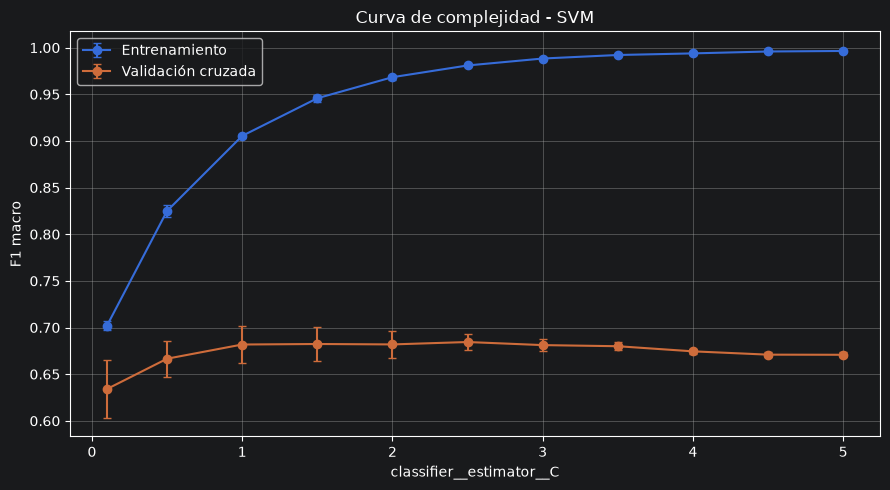

In [27]:
graficar_complejidad(grid_search_nn, nombre="Red neuronal", param_name="classifier__model__learning_rate")
graficar_complejidad(best_model_svm,nombre="SVM",param_name="classifier__estimator__C",grid=grid_search_svm,log_x=False)

===== SVM - Test =====
Accuracy:            0.7623
Precision (macro):   0.6984
Precision (weighted):0.7670
Recall (macro):      0.7157
F1 (macro):          0.7065
F1 (weighted):       0.7643
ROC-AUC (OvR macro): 0.8822   (usando decision_function)

Reporte por clase:

              precision    recall  f1-score   support

           N       0.58      0.64      0.61       110
         NEU       0.83      0.81      0.82       484
           P       0.68      0.70      0.69       138

    accuracy                           0.76       732
   macro avg       0.70      0.72      0.71       732
weighted avg       0.77      0.76      0.76       732



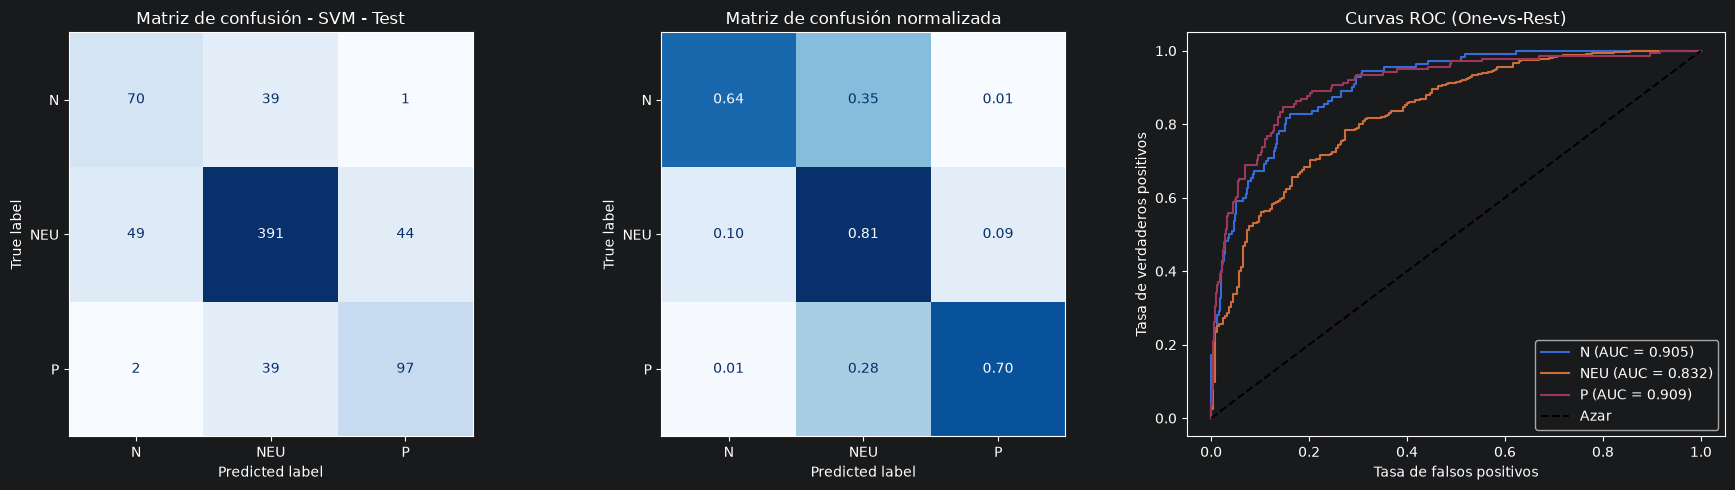

{'accuracy': 0.7622950819672131,
 'precision_macro': 0.6984332292012839,
 'precision_weighted': 0.7669525953013273,
 'recall_macro': 0.7157044755858984,
 'f1_macro': 0.706494793535717,
 'f1_weighted': 0.7642557405992116,
 'roc_auc': 0.8821925012347821,
 'y_pred': array(['P', 'NEU', 'P', 'NEU', 'P', 'NEU', 'NEU', 'P', 'N', 'P', 'NEU',
        'P', 'NEU', 'P', 'N', 'NEU', 'NEU', 'NEU', 'N', 'NEU', 'N', 'NEU',
        'NEU', 'N', 'NEU', 'NEU', 'NEU', 'NEU', 'NEU', 'NEU', 'NEU', 'NEU',
        'N', 'NEU', 'N', 'NEU', 'NEU', 'NEU', 'P', 'NEU', 'NEU', 'P', 'P',
        'NEU', 'NEU', 'P', 'NEU', 'NEU', 'NEU', 'NEU', 'N', 'NEU', 'NEU',
        'NEU', 'NEU', 'NEU', 'NEU', 'NEU', 'NEU', 'NEU', 'NEU', 'P', 'NEU',
        'NEU', 'NEU', 'NEU', 'P', 'NEU', 'P', 'NEU', 'P', 'NEU', 'NEU',
        'P', 'NEU', 'NEU', 'NEU', 'NEU', 'NEU', 'NEU', 'N', 'NEU', 'NEU',
        'NEU', 'NEU', 'NEU', 'NEU', 'NEU', 'NEU', 'N', 'P', 'NEU', 'P',
        'P', 'N', 'NEU', 'NEU', 'NEU', 'NEU', 'P', 'N', 'N', 'NEU', 'N

In [28]:
evaluar_modelo(best_model_nn, nombre="Red neuronal - Test")
evaluar_modelo(best_model_svm, nombre="SVM - Test")

In [29]:
from sklearn.calibration import CalibratedClassifierCV

tweets = [
    "A veces funciona, a veces no",
    "Nos puede llegar a sacar el trabajo, es un peligro",
    "Es una buena herramienta",
]

# La calibración es responsabilidad de quien llama a la función
best_pipe = grid_search_svm.best_estimator_
clf_best = best_pipe.named_steps["classifier"]

calibrated_clf = CalibratedClassifierCV(clf_best, method="sigmoid", cv=3)
calibrated_clf.fit(X_trval_prepro, y_trval)

resultado = predecir_tweets(calibrated_clf,tweets,nombre="Predicción de tweets SVM")

predecir_tweets(best_model_nn, tweets, nombre="Predicción de tweets Red neuronal")

===== Predicción de tweets SVM =====
                                             tweet prediccion      N    NEU      P
                      A veces funciona, a veces no        NEU 0.0413 0.8118 0.1470
Nos puede llegar a sacar el trabajo, es un peligro          N 0.6284 0.3371 0.0345
                          Es una buena herramienta        NEU 0.0106 0.7124 0.2770


NameError: name 'best_model_nn' is not defined